# Zoom — Logistic Regression — Breast Cancer Wisconsin (Diagnostic)

**Course:** UE 5BM753 — Supervised and Unsupervised Learning for Biology
**Part of:** the Breast Cancer Wisconsin (Diagnostic) final report, split into
per-step notebooks. See `README.md` for the overall narrative and conclusion.

**Question addressed here:** can we reliably predict the diagnosis from the selected features?

Tunes and evaluates the final Logistic Regression model, on the features selected in `04_Feature_Selection.ipynb`.

## Setup

Defines the paths used below and imports the reusable functions kept in
`01_scripts/`.

In [19]:
## Setup
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

sys.path.append(os.path.join("..", "01_scripts"))
from evaluation import evaluate_classifier
from plots import plot_roc_curves, plot_confusion_matrices

RANDOM_STATE = 42
CV_FOLDS = 10
RESULTS_DIR = os.path.join("..", "04_results")
FIGURES_DIR = os.path.join("..", "05_figures")
PROCESSED_DATA_DIR = os.path.join("..", "02_data", "processed")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

## Hyperparameter tuning

A 10-fold cross-validated grid search tunes the regularization strength `C` of the
model over a logarithmic grid. Recall is optimized to strictly minimize missed malignant 
cases. To ensure coefficient stability across correlated features, the 1-Standard Error 
(1-SE) rule is applied: selecting the simplest model (strongest regularization / smallest C) 
that achieves a recall within one standard error of the absolute maximum.

Absolute Best C (max recall): 30.3920
1-SE Rule Optimal C: 0.3857
Mean Recall (1-SE C): 0.9381


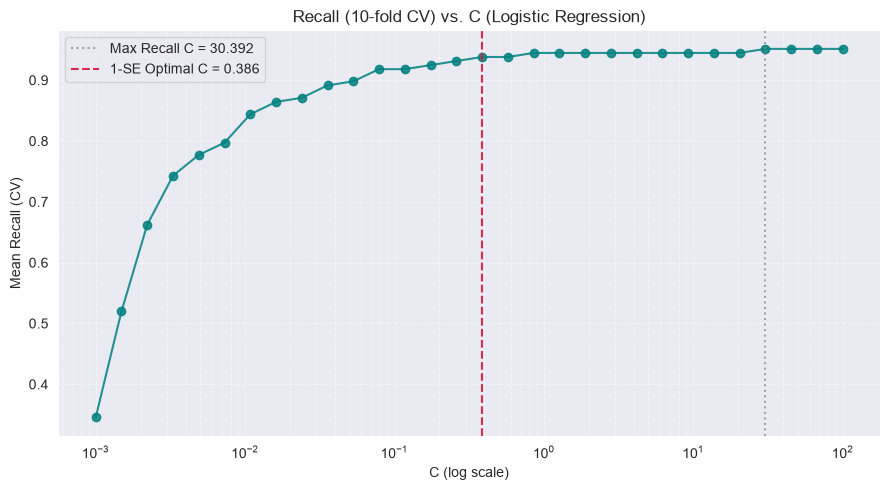

In [20]:
train_df = pd.read_csv(os.path.join(PROCESSED_DATA_DIR, "04_train_selected_features.csv"))
X_train_sel = train_df.drop(columns=["label"]).values
y_train = train_df["label"].values

MODEL_NAME = "Logistic Regression (selected features)"

param_grid = {"C": np.logspace(-3, 2, 30)}

grid_logreg = GridSearchCV(
    LogisticRegression(random_state=RANDOM_STATE, max_iter=5000),
    param_grid, cv=CV_FOLDS, scoring='recall', n_jobs=-1
)
grid_logreg.fit(X_train_sel, y_train)

res = pd.DataFrame(grid_logreg.cv_results_)
best_row = res.loc[res["mean_test_score"].idxmax()]
one_se_floor = best_row["mean_test_score"] - (best_row["std_test_score"] / np.sqrt(CV_FOLDS))
one_se_C = res.loc[res["mean_test_score"] >= one_se_floor, "param_C"].astype(float).min()

print(f"Absolute Best C (max recall): {grid_logreg.best_params_['C']:.4f}")
print(f"1-SE Rule Optimal C: {one_se_C:.4f}")
print(f"Mean Recall (1-SE C): {res.loc[res['param_C'] == one_se_C, 'mean_test_score'].values[0]:.4f}\n")

plt.figure(figsize=(9, 5))
plt.plot(res["param_C"].astype(float), res["mean_test_score"], marker='o', color='teal', alpha=0.85)
plt.axvline(grid_logreg.best_params_['C'], linestyle=':', color='grey', alpha=0.7, 
            label=f"Max Recall C = {grid_logreg.best_params_['C']:.3f}")
plt.axvline(one_se_C, linestyle='--', color='crimson', alpha=0.9, 
            label=f"1-SE Optimal C = {one_se_C:.3f}")
plt.xscale('log')
plt.title(f"Recall ({CV_FOLDS}-fold CV) vs. C (Logistic Regression)")
plt.xlabel("C (log scale)")
plt.ylabel("Mean Recall (CV)")
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "05_logreg_c_tuning.png"))
plt.show()

**Findings.** The recall curve hits a plateau across higher values of C. Applying the 1-SE rule selects a substantially smaller optimal C of 0.3857, applying a much stronger L2 penalty than the absolute maximum C (30.3920). This simpler, strictly regularized model maintains peak diagnostic sensitivity with a mean cross-validated recall of 0.9381, preventing the algorithm from overfitting collinear variables.

## Evaluation

The model is refit using the 1-SE `C` on the entire restricted training set. It is then evaluated on the held-out test set.

--- Final evaluation (held-out test set) ---


,accuracy,precision,recall,f1,f2,roc_auc
Logistic Regression (selected features),0.9825,1.0,0.9531,0.976,0.9621,0.9971


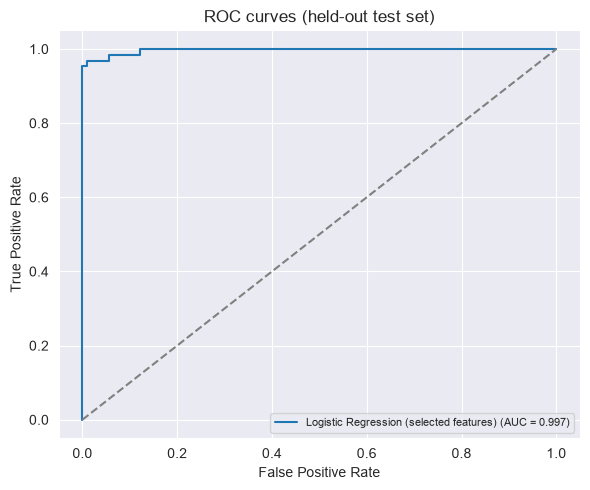

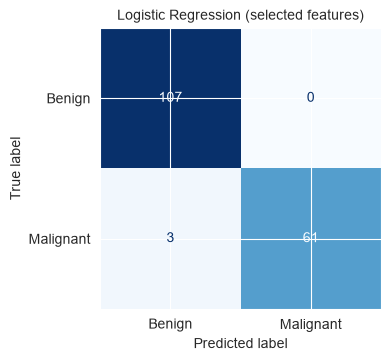

In [21]:
test_df = pd.read_csv(os.path.join(PROCESSED_DATA_DIR, "04_test_selected_features.csv"))
X_test_sel = test_df.drop(columns=["label"]).values
y_test = test_df["label"].values

best_logreg = LogisticRegression(C=one_se_C, random_state=RANDOM_STATE, max_iter=5000).fit(X_train_sel, y_train)
models_dict = {MODEL_NAME: best_logreg}

metrics_logreg = evaluate_classifier(best_logreg, X_train_sel, y_train, X_test_sel, y_test)
df_results_logreg = pd.DataFrame([metrics_logreg], index=[MODEL_NAME])
df_results_logreg.to_csv(os.path.join(RESULTS_DIR, "05_logreg_final_metrics.csv"))

print("--- Final evaluation (held-out test set) ---")
display(df_results_logreg.round(4))

plot_roc_curves(
    classifiers=models_dict, X_tr=X_train_sel, y_tr=y_train, X_te=X_test_sel, y_te=y_test,
    out_path=os.path.join(FIGURES_DIR, "05_logreg_roc_curve.png"))

plot_confusion_matrices(
    classifiers=models_dict, X_tr=X_train_sel, y_tr=y_train, X_te=X_test_sel, y_te=y_test,
    out_path=os.path.join(FIGURES_DIR, "05_logreg_confusion_matrix.png")
)

**Findings.** On the held-out test set, the 1-SE tuned model misses 3 malignant cases (recall = 0.9531), successfully preserving the clinical priority of the project. Notably, the stronger regularization eliminated all false alarms: the model correctly classified all 107 benign cases, achieving a perfect precision of 1.0. The ROC-AUC of 0.9971 confirms that the model correctly ranks malignant cases above benign ones with extreme efficiency.

## Model interpretation
 
A 1,000-iteration bootstrap resampling establishes 95% confidence intervals for the coefficients. Since features are standardized, coefficients indicate the change in log-odds of malignancy per +1 standard deviation. 

--- Logistic Regression coefficients (standardized features) ---


,coefficient,ci_low,ci_high,odds_ratio_per_SD
radius_mean,1.960,1.528,2.306,7.096
texture_worst,1.274,1.018,1.563,3.576
radius_se,1.263,0.711,1.687,3.537
concave_points_worst,0.964,0.720,1.288,2.622
concave_points_mean,0.895,0.593,1.257,2.448
symmetry_worst,0.649,0.248,0.977,1.914
smoothness_worst,0.504,0.145,0.827,1.656


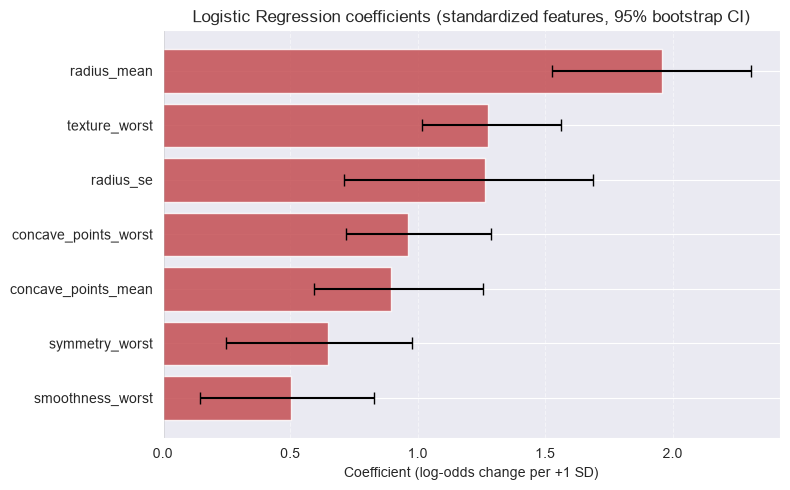

In [22]:
selected_features = train_df.drop(columns=["label"]).columns.tolist()
coefs = pd.Series(best_logreg.coef_[0], index=selected_features)
 
N_BOOTSTRAP = 1000
rng = np.random.default_rng(RANDOM_STATE)
boot_coefs = np.empty((N_BOOTSTRAP, len(selected_features)))
 
for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(X_train_sel), len(X_train_sel))
    boot_model = LogisticRegression(C=best_logreg.C, random_state=RANDOM_STATE, max_iter=5000)
    boot_model.fit(X_train_sel[idx], y_train[idx])
    boot_coefs[b] = boot_model.coef_[0]
 
ci_low, ci_high = np.percentile(boot_coefs, [2.5, 97.5], axis=0)
 
coef_table = pd.DataFrame({
    "coefficient": coefs,
    "ci_low": ci_low,
    "ci_high": ci_high,
    "odds_ratio_per_SD": np.exp(coefs),
}).sort_values("coefficient", key=np.abs, ascending=False)
coef_table.to_csv(os.path.join(RESULTS_DIR, "05_logreg_coefficients.csv"))
 
print("--- Logistic Regression coefficients (standardized features) ---")
display(coef_table.round(3))
 
plot_df = coef_table.iloc[::-1]
err_low = np.clip(plot_df["coefficient"] - plot_df["ci_low"], 0, None)
err_high = np.clip(plot_df["ci_high"] - plot_df["coefficient"], 0, None)
 
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_df.index, plot_df["coefficient"],
        color=np.where(plot_df["coefficient"] > 0, "#C44E52", "#4C72B0"), alpha=0.85,
        xerr=[err_low, err_high], capsize=4)
ax.axvline(0, color="grey", linewidth=1)
ax.set_xlabel("Coefficient (log-odds change per +1 SD)")
ax.set_title("Logistic Regression coefficients (standardized features, 95% bootstrap CI)")
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "05_logreg_coefficients.png"))
plt.show()

**Findings.** The stronger regularization derived from the 1-SE rule ensures mathematical stability. Correlated features now correctly share the predictive weight without artificial deflation. Nuclear size (`radius_mean`) remains the defining predictor, reliably increasing the odds of malignancy by roughly a factor of 7 per standard deviation. No intervals cross zero, confirming that every feature actively contributes to the diagnosis.

## Discussion

By prioritizing recall and employing the 1-SE rule, the Logistic Regression model successfully maintains strict diagnostic safety while dramatically improving its statistical robustness. It misses only 3 malignant cases out of 64 on the test set. Furthermore, the stronger L2 regularization proved highly beneficial: by preventing the model from assigning arbitrary weights to correlated features, it completely eliminated false positives on the test set (precision = 1.0).

The stabilized coefficients align logically with clinical pathology. The penalty appropriately distributes the log-odds impact across correlated measurements. Nuclear size (`radius_mean`, `radius_se`) and cellular texture (`texture_worst`) remain the principal drivers of malignancy prediction, mirroring visual assessments performed by oncologists. 

**Limitations.** While the 1-SE optimization yielded perfect precision (no false alarms) on this specific held-out test set, this 1.0 metric is susceptible to sample variance and is unlikely to remain perfectly zero in a broader clinical deployment. The model's coefficients reflect mathematical decision boundaries on standardized data, not direct causal biological relationships. Finally, the data originates from a single institution, meaning external, multi-center validation is required before these specific log-odds thresholds can be generalized to other populations.